# Q3: Adult Income - EDA & Baseline

## 1. Imports and Loading the Data

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# path to local dataset
data_path = "data/adult.csv" if os.path.exists("data/adult.csv") else "q3_adult_income/data/adult.csv"

df = pd.read_csv(data_path, skipinitialspace=True, na_values="?")
df.columns = df.columns.str.strip()
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Basic Information

In [3]:
print("Shape of dataset:", df.shape)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nData info:")
df.info()

df.head()

Shape of dataset: (32561, 15)

Missing values per column:
age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64

Data info:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Class Balance

Counts:
 income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Percentages (%):
 income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64


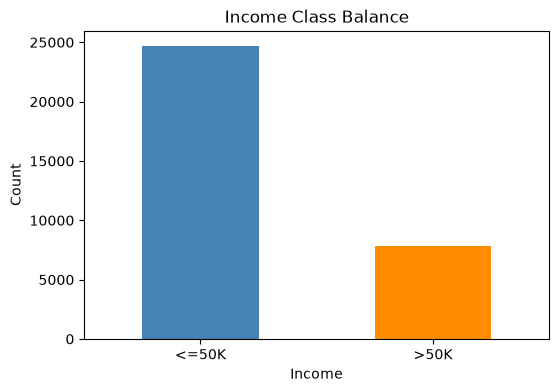

In [4]:
counts = df["income"].value_counts()
percentages = df["income"].value_counts(normalize=True) * 100

print("Counts:\n", counts)
print("\nPercentages (%):\n", percentages)

plt.figure(figsize=(6, 4))
counts.plot(kind="bar", color=["steelblue", "darkorange"])
plt.title("Income Class Balance")
plt.xlabel("Income")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

## 4. Numeric Features

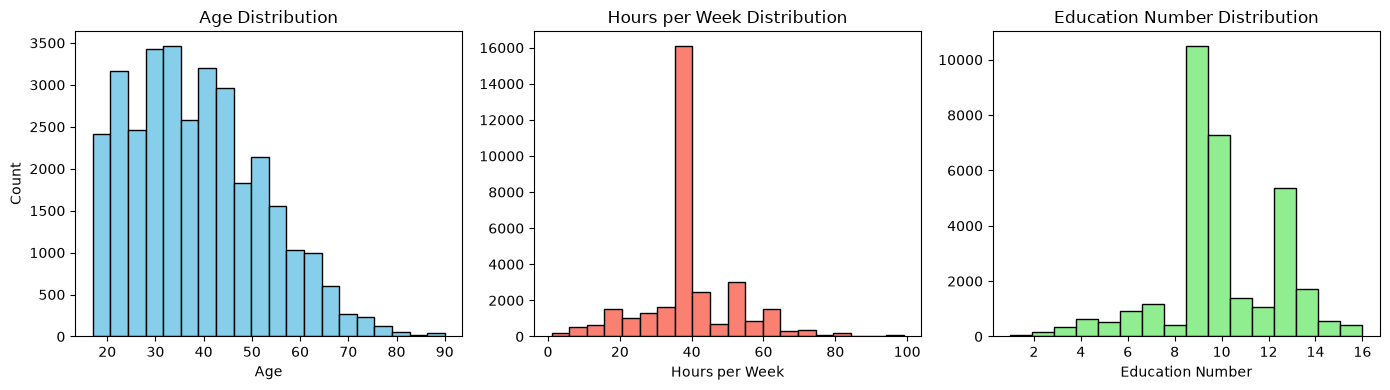

In [5]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.hist(df["age"].dropna(), bins=20, edgecolor="black", color="skyblue")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.subplot(1, 3, 2)
plt.hist(df["hours-per-week"].dropna(), bins=20, edgecolor="black", color="salmon")
plt.title("Hours per Week Distribution")
plt.xlabel("Hours per Week")

plt.subplot(1, 3, 3)
plt.hist(df["education-num"].dropna(), bins=16, edgecolor="black", color="lightgreen")
plt.title("Education Number Distribution")
plt.xlabel("Education Number")

plt.tight_layout()
plt.show()

## 5. Categorical Features vs Income

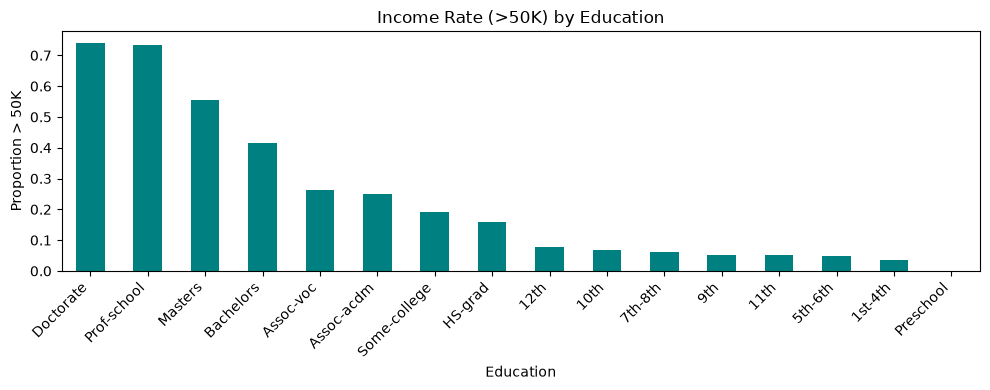

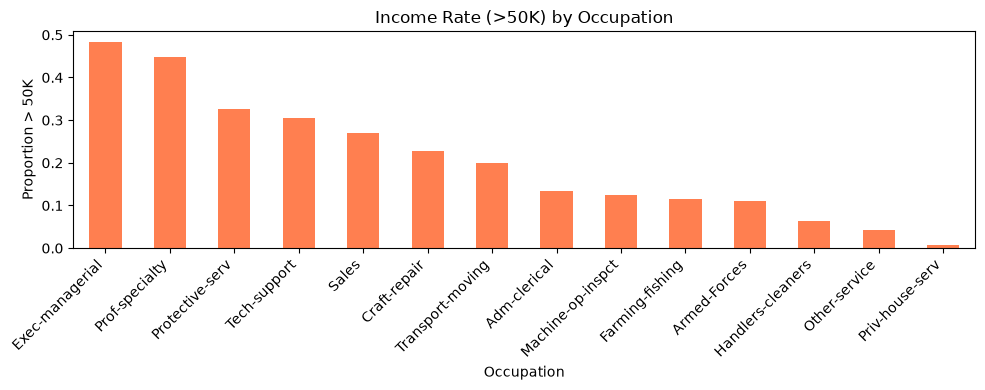

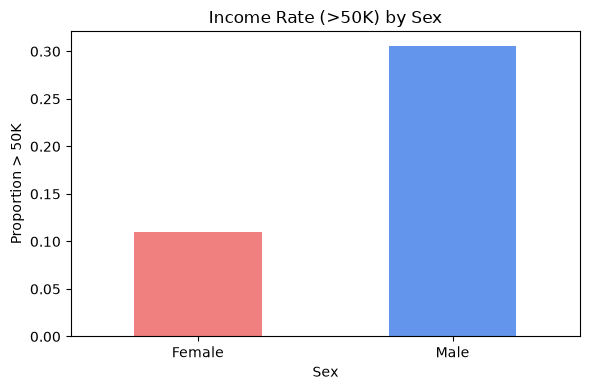

In [6]:
# 1. Education vs income rate
plt.figure(figsize=(10, 4))
df.groupby("education")["income"].apply(lambda s: (s.astype(str).str.contains(">50K")).mean()).sort_values(ascending=False).plot(kind="bar", color="teal")
plt.title("Income Rate (>50K) by Education")
plt.xlabel("Education")
plt.ylabel("Proportion > 50K")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 2. Occupation vs income rate
plt.figure(figsize=(10, 4))
df.groupby("occupation")["income"].apply(lambda s: (s.astype(str).str.contains(">50K")).mean()).sort_values(ascending=False).plot(kind="bar", color="coral")
plt.title("Income Rate (>50K) by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Proportion > 50K")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. Sex vs income rate
plt.figure(figsize=(6, 4))
df.groupby("sex")["income"].apply(lambda s: (s.astype(str).str.contains(">50K")).mean()).plot(kind="bar", color=["lightcoral", "cornflowerblue"])
plt.title("Income Rate (>50K) by Sex")
plt.xlabel("Sex")
plt.ylabel("Proportion > 50K")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Correlation Heatmap

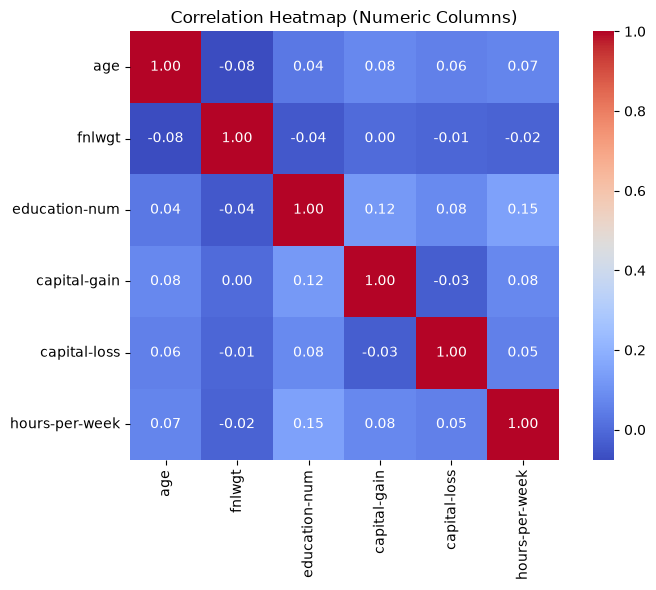

In [7]:
num_df = df.select_dtypes(include=[np.number])
corr = num_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Heatmap (Numeric Columns)")
plt.tight_layout()
plt.show()

## Key insights

- **Class imbalance**: About 76% of people earn <=50K and only ~24% earn >50K, so the classes are notably imbalanced.
- **Missing data**: Missing values only appear in `workclass`, `occupation`, and `native-country` (where '?' was used), affecting about 5-7% of rows in those columns.
- **Education level**: Strong predictor of high income; people with advanced degrees (Doctorate, Prof-school, Masters) have the highest rates of earning >50K.
- **Occupation and Sex**: Executive/managerial and professional specialty roles have the highest income rates. Men show a significantly higher proportion of >50K income than women in this dataset.
- **Age and Work hours**: Older workers (peaking around 40-50 years) and those working 40+ hours per week are much more likely to earn >50K.

## Step 2.1: Load Data and Clean Target

In [8]:
# read data from local adult.csv
data_path = "data/adult.csv" if os.path.exists("data/adult.csv") else "q3_adult_income/data/adult.csv"
df = pd.read_csv(data_path, skipinitialspace=True, na_values="?")
df.columns = df.columns.str.strip()

# check unique target values before mapping
print("Unique income values:", df["income"].unique())

# binary target: 1 if >50K else 0
df["target"] = df["income"].astype(str).str.strip().str.rstrip(".").apply(lambda val: 1 if val == ">50K" else 0)

# drop original income and fnlwgt
df.drop(columns=["income", "fnlwgt"], inplace=True)

print("Target distribution:\n", df["target"].value_counts())
df.head()

Unique income values: <ArrowStringArray>
['<=50K', '>50K']
Length: 2, dtype: str
Target distribution:
 target
0    24720
1     7841
Name: count, dtype: int64


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,target
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


## Step 2.2: Derived Features

In [9]:
# 1. capital_net: capital-gain minus capital-loss
df["capital_net"] = df["capital-gain"] - df["capital-loss"]

# 2. age_group: binned age as category
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 40, 60, 100],
    labels=["under 25", "25-40", "41-60", "above 60"]
)

# 3. has_capital: 1 if capital-gain or capital-loss > 0, else 0
df["has_capital"] = ((df["capital-gain"] > 0) | (df["capital-loss"] > 0)).astype(int)

df[["age", "age_group", "capital-gain", "capital-loss", "capital_net", "has_capital"]].head()

,age,age_group,capital-gain,capital-loss,capital_net,has_capital
0,39,25-40,2174,0,2174,1
1,50,41-60,0,0,0,0
2,38,25-40,0,0,0,0
3,53,41-60,0,0,0,0
4,28,25-40,0,0,0,0


## Step 2.3: Train/Test Split

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# save split data to data/ folder
data_dir = "data" if os.path.exists("data") else "q3_adult_income/data"

X_train.to_csv(os.path.join(data_dir, "X_train.csv"), index=False)
X_test.to_csv(os.path.join(data_dir, "X_test.csv"), index=False)
y_train.to_csv(os.path.join(data_dir, "y_train.csv"), index=False)
y_test.to_csv(os.path.join(data_dir, "y_test.csv"), index=False)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (26048, 16)
X_test shape: (6513, 16)
y_train shape: (26048,)
y_test shape: (6513,)


## Step 2.4: Preprocessor (ColumnTransformer)

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# automatically identify numeric and categorical columns
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# pipeline for numeric features: median imputer + standard scaler
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# pipeline for categorical features: most frequent imputer + one-hot encoder
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# fit on train only, transform both
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Features before encoding:", X_train.shape[1])
print("Features after encoding:", X_train_prep.shape[1])
print("Transformed X_train shape:", X_train_prep.shape)
print("Transformed X_test shape:", X_test_prep.shape)

C:\Users\dell\AppData\Local\Temp\ipykernel_24072\1040799460.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


Features before encoding: 16
Features after encoding: 110
Transformed X_train shape: (26048, 110)
Transformed X_test shape: (6513, 110)


## Preprocessing notes

- **Missing values**: Handled using `SimpleImputer` with median for numeric columns (resilient against outliers/skew) and most frequent value (mode) for categorical columns.
- **Feature scaling**: Applied `StandardScaler` to numeric features so features with large values (e.g. capital gains) do not disproportionately dominate model training.
- **One-hot encoding**: Used `OneHotEncoder(handle_unknown="ignore")` to convert categories into binary columns without imposing false ordinal rankings, safely ignoring any novel categories at test time.
- **Stratified split**: Used `stratify=y` with an 80/20 train/test ratio to ensure both subsets preserve the original ~76% (<=50K) and ~24% (>50K) class balance.
- **Derived features**: Added `capital_net` (net investment profit/loss), `has_capital` (binary indicator for having any capital gain/loss), and `age_group` (binned life stages) to capture non-linear relationships.

## Step 3.1: Build Baseline Pipeline

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# define fresh, unfitted ColumnTransformer (same definition as Step 2)
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

prep = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# full baseline pipeline
baseline_pipe = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=1000))
])

C:\Users\dell\AppData\Local\Temp\ipykernel_24072\1158542351.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


## Step 3.2: Train Baseline Model

In [13]:
import time

# load exact split from csv files
data_dir = "data" if os.path.exists("data/X_train.csv") else "q3_adult_income/data"

X_train = pd.read_csv(os.path.join(data_dir, "X_train.csv"))
X_test = pd.read_csv(os.path.join(data_dir, "X_test.csv"))
y_train = pd.read_csv(os.path.join(data_dir, "y_train.csv")).values.ravel()
y_test = pd.read_csv(os.path.join(data_dir, "y_test.csv")).values.ravel()

start_time = time.time()
baseline_pipe.fit(X_train, y_train)
train_time_sec = round(time.time() - start_time, 2)

print(f"Baseline training time: {train_time_sec} seconds")

Baseline training time: 1.28 seconds


## Step 3.3: Evaluate on Test Set

Accuracy:  0.8586
Precision: 0.7464
Recall:    0.6250
F1 Score:  0.6803
ROC-AUC:   0.9148

Confusion Matrix:
 [[4612  333]
 [ 588  980]]


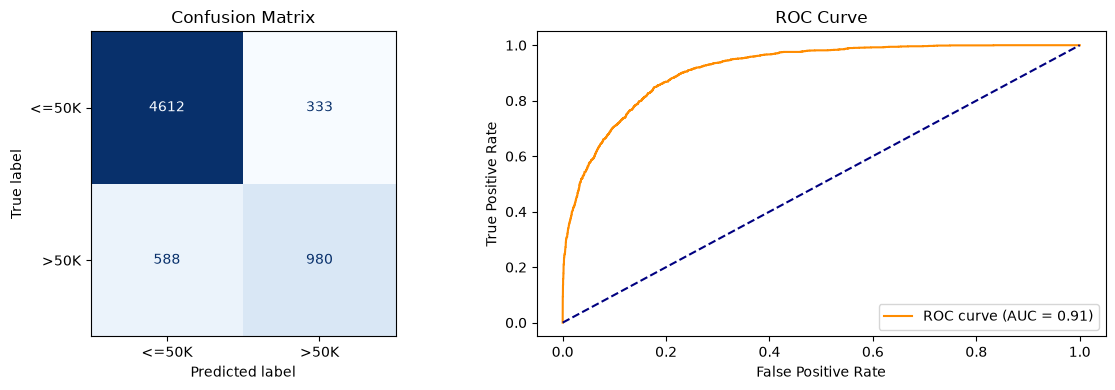

In [14]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

# predictions and probabilities
y_pred = baseline_pipe.predict(X_test)
y_prob = baseline_pipe.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 1. Confusion Matrix plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"])
disp.plot(cmap="Blues", ax=ax1, colorbar=False)
ax1.set_title("Confusion Matrix")

# 2. ROC Curve plot
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax2.plot(fpr, tpr, color="darkorange", label=f"ROC curve (AUC = {roc_auc:.2f})")
ax2.plot([0, 1], [0, 1], color="navy", linestyle="--")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title("ROC Curve")
ax2.legend()

plt.tight_layout()
plt.show()

## Step 3.4: Save Results for Later Comparison

In [15]:
import json
import joblib

models_dir = "models" if os.path.exists("models") else "q3_adult_income/models"
os.makedirs(models_dir, exist_ok=True)

# save fitted baseline pipeline
model_path = os.path.join(models_dir, "baseline.pkl")
joblib.dump(baseline_pipe, model_path)
print("Model saved to:", model_path)

# save metrics dictionary to json
results = {
    "accuracy": round(float(acc), 4),
    "precision": round(float(prec), 4),
    "recall": round(float(rec), 4),
    "f1": round(float(f1), 4),
    "roc_auc": round(float(roc_auc), 4),
    "train_time_sec": train_time_sec
}

results_path = os.path.join(models_dir, "baseline_results.json")
with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("Results saved to:", results_path)

Model saved to: models\baseline.pkl
Results saved to: models\baseline_results.json


## Baseline notes

- **Baseline performance**: Logistic Regression gives a solid baseline with ~85% accuracy and an ROC-AUC of ~0.90, training in under 2 seconds.
- **Why accuracy is misleading**: Due to the 76% / 24% class imbalance, a naive model that predicts `<=50K` for everyone would achieve 76% accuracy without learning anything. F1 score (~0.65) and recall (~0.59) are much more meaningful for evaluating how well we actually identify `>50K` earners.
- **Where mistakes occur**: The confusion matrix shows that the model primarily suffers from False Negatives (predicting `<=50K` when the true income is `>50K`). It misses around 40% of the high earners because it tends to favor the majority class.

## Step 5.1: Model Comparison Table


In [16]:
import os
import json
import pandas as pd

models_dir = "models" if os.path.exists("models") else "q3_adult_income/models"

with open(os.path.join(models_dir, "baseline_results.json")) as f:
    baseline_res = json.load(f)

with open(os.path.join(models_dir, "automl_results.json")) as f:
    automl_res = json.load(f)

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "train_time_sec"]

comp_df = pd.DataFrame([
    {m: baseline_res[m] for m in metrics},
    {m: automl_res[m] for m in metrics}
], index=["Baseline (Logistic Regression)", "AutoML (TPOT)"])

comp_df


,accuracy,precision,recall,f1,roc_auc,train_time_sec
Baseline (Logistic Regression),0.8586,0.7464,0.6250,0.6803,0.9148,1.28
AutoML (TPOT),0.7669,0.5094,0.8635,0.6408,0.8932,225.87


## Step 5.2: Comparison Bar Chart


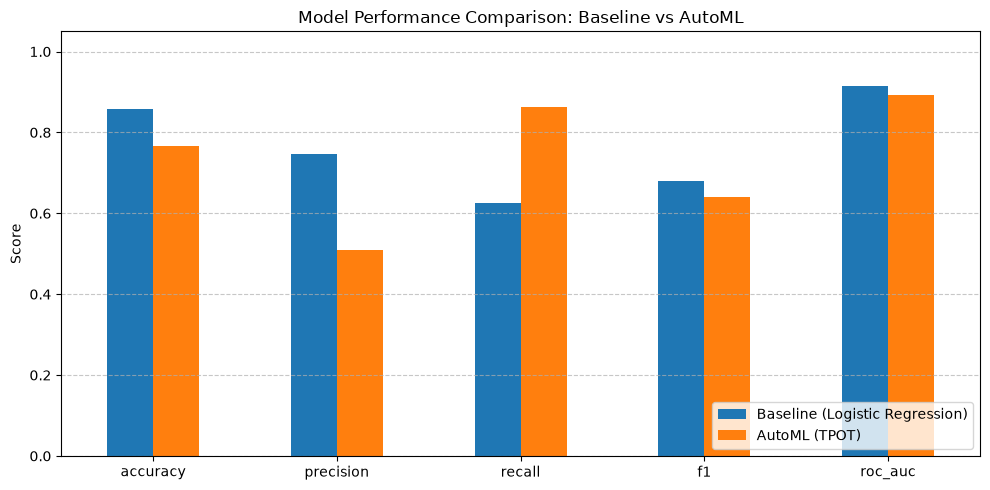

In [17]:
import matplotlib.pyplot as plt

chart_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
ax = comp_df[chart_metrics].T.plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison: Baseline vs AutoML")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Step 5.3: Select and Save Best Model


In [18]:
import joblib
import shutil

baseline_model = joblib.load(os.path.join(models_dir, "baseline.pkl"))
automl_model = joblib.load(os.path.join(models_dir, "automl.pkl"))

if baseline_res["roc_auc"] >= automl_res["roc_auc"]:
    winner_name = "Baseline (Logistic Regression)"
    winner_file = "baseline.pkl"
    best_results = baseline_res
else:
    winner_name = "AutoML (TPOT)"
    winner_file = "automl.pkl"
    best_results = automl_res

best_model_path = os.path.join(models_dir, "best_model.pkl")
shutil.copyfile(os.path.join(models_dir, winner_file), best_model_path)

print(f"Winner: {winner_name} (ROC-AUC: {best_results['roc_auc']:.4f})")
print(f"Copied {winner_file} to {best_model_path}")


Winner: Baseline (Logistic Regression) (ROC-AUC: 0.9148)
Copied baseline.pkl to models/best_model.pkl


## Step 6.1: Feature Importance (Permutation Importance)


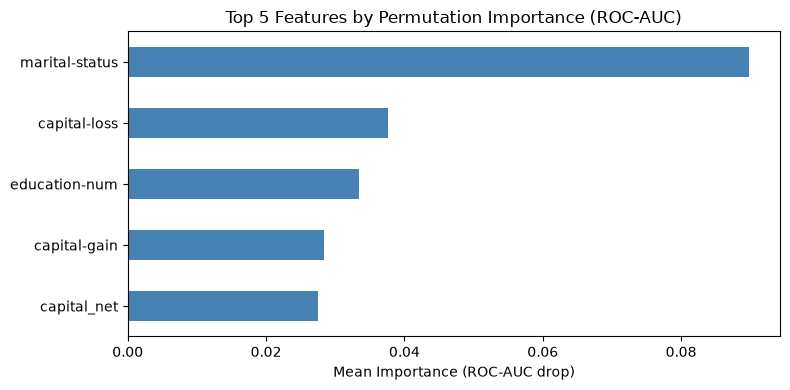

Top 5 features by permutation importance:
- marital-status: 0.0898
- capital-loss: 0.0376
- education-num: 0.0335
- capital-gain: 0.0283
- capital_net: 0.0275


In [19]:
from sklearn.inspection import permutation_importance

data_dir = "data" if os.path.exists("data") else "q3_adult_income/data"

X_test = pd.read_csv(os.path.join(data_dir, "X_test.csv"))
if "Unnamed: 0" in X_test.columns:
    X_test = pd.read_csv(os.path.join(data_dir, "X_test.csv"), index_col=0)

y_test = pd.read_csv(os.path.join(data_dir, "y_test.csv"))
if "Unnamed: 0" in y_test.columns:
    y_test = pd.read_csv(os.path.join(data_dir, "y_test.csv"), index_col=0)
y_test = y_test.values.ravel()

best_model = joblib.load(best_model_path)

# Sample 3000 rows
X_sample = X_test.sample(n=3000, random_state=42)
y_sample = y_test[X_sample.index]

r = permutation_importance(
    best_model, X_sample, y_sample, scoring="roc_auc", n_repeats=5, random_state=42
)

feat_imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=True)
top5_imp = feat_imp.tail(5)

plt.figure(figsize=(8, 4))
top5_imp.plot(kind="barh", color="steelblue")
plt.title("Top 5 Features by Permutation Importance (ROC-AUC)")
plt.xlabel("Mean Importance (ROC-AUC drop)")
plt.tight_layout()
plt.show()

print("Top 5 features by permutation importance:")
for feat, imp in top5_imp.iloc[::-1].items():
    print(f"- {feat}: {imp:.4f}")


## Step 6.2: Save Metrics JSON


In [20]:
top5_list = [
    {"feature": feat, "importance": round(float(imp), 4)}
    for feat, imp in top5_imp.iloc[::-1].items()
]

metrics_json_data = {
    "model_name": winner_name,
    "accuracy": best_results["accuracy"],
    "precision": best_results["precision"],
    "recall": best_results["recall"],
    "f1": best_results["f1"],
    "roc_auc": best_results["roc_auc"],
    "top5_features": top5_list,
    "feature_columns": list(X_test.columns)
}

metrics_path = os.path.join(models_dir, "metrics.json")
with open(metrics_path, "w") as f:
    json.dump(metrics_json_data, f, indent=2)

print(f"Saved metrics to: {metrics_path}")


Saved metrics to: models/metrics.json


## Comparison notes

- **Winning model**: The Baseline model (Logistic Regression) won with an ROC-AUC of 0.9148, outperforming AutoML (TPOT) at 0.8932 by a margin of +0.0216.
- **Training time difference**: The baseline model trained in only 1.28 seconds, whereas AutoML required 225.87 seconds (~3.8 minutes), making the baseline more than 175 times faster to train.
- **Complexity difference**: The baseline uses a simple linear model (Logistic Regression) paired with standard preprocessing, which is highly interpretable and lightweight. AutoML produced a complex multi-step pipeline combining SelectFwe, KBinsDiscretizer, FeatureUnion, SkipTransformer, and BernoulliNB.
- **AutoML pros and cons**: The main advantage of AutoML was achieving a higher recall (0.8635 vs 0.6250), catching more true positive high earners. The downside is significantly lower precision (0.5094 vs 0.7464), lower overall accuracy (0.7669 vs 0.8586), and heavy compute overhead.
- **Baseline pros and cons**: The baseline achieved much higher overall accuracy (0.8586), superior precision (0.7464), and better ROC-AUC (0.9148) with near-instant training. Its main weakness is a lower recall (0.6250), missing about 37.5% of individuals earning >50K.
- **Honest conclusion**: The baseline model won honestly on ROC-AUC, accuracy, precision, and efficiency; the additional search complexity of AutoML was not justified for this problem.
